# Email communication Network Analysis

This notebook analyzes the email communication network from the University Rovira I Virgili in Tarragona  dataset.
It creates a network graph and computes various network statistics. It also compares the emperical network with three canonical model networks and calculates different centrality measures.

Based on the example code provided in the Model-Based-Decisions-Code- Week 2 - Networks GitHub
(Source: https://github.com/mhlees/Model-Based-Decisions-Code/tree/main/Week%202%20-%20Networks)

# Email comunication Database
**Data format: MTX**
(Source: https://networkrepository.com/ia-email-univ.php)

## Import Libraries

In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import seaborn as sns
from scipy.io import mmread

# Set matplotlib to display plots inline
%matplotlib inline

# Set style for better looking plots
plt.style.use('default')
sns.set_palette("husl")

## Data Loading Functions

In [3]:
def load_email_data(filepath):
    """
    Load email data from MTX file.
    
    Args:
        filepath (str): Path to the email data file
        
    Returns:
        matrix: The email communication matrix
    """ 
    
    # Load data
    matrix = mmread(filepath).tocsr()
    
    print("Loading email communication data...")

    print(f"Loaded {matrix.shape[0]} users")
    print(f"Data shape: {matrix.shape}")
    
    return matrix

## Network Creation Functions

In [4]:
 def create_email_network(matrix):
    """
    Creates a network graph from email communication data.
    
    Args:
        matrix: Matrix containing the email communication data
        
    Returns:
        networkx.Graph: Undirected graph of email connections
   """ 
    # Create undirected graph
    G = nx.from_scipy_sparse_array(matrix, create_using=nx.Graph())

    # Remove self-loops
    G.remove_edges_from(nx.selfloop_edges(G))
    
    print(f"Network created with {G.number_of_nodes()} users and {G.number_of_edges()} connections")
    
    return G 

## Visualization Functions

In [5]:
def plot_degree_distribution(G):
    """
    Plot the degree distribution of the network.
    
    Args:
        G (networkx.Graph): Network graph
    """
    print("Plotting degree distribution...")
    
    # Get degree sequence
    degrees = [G.degree(n) for n in G.nodes()]
    degree_counts = Counter(degrees)
    
    # Create figure with subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Linear scale plot
    degrees_list = list(degree_counts.keys())
    counts_list = list(degree_counts.values())
    
    ax1.bar(degrees_list, counts_list, alpha=0.7, color='skyblue', edgecolor='black')
    ax1.set_xlabel('Degree')
    ax1.set_ylabel('Number of users')
    ax1.set_title('Degree Distribution (Linear Scale)')
    ax1.grid(True, alpha=0.3)
    
    # Log-log scale plot
    ax2.loglog(degrees_list, counts_list, 'bo', alpha=0.7, markersize=4)
    ax2.set_xlabel('Degree (log scale)')
    ax2.set_ylabel('Number of users (log scale)')
    ax2.set_title('Degree Distribution (Log-Log Scale)')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('degree_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print basic statistics
    print(f"\nDegree Distribution Statistics:")
    print(f"Mean degree: {np.mean(degrees):.2f}")
    print(f"Median degree: {np.median(degrees):.2f}")
    print(f"Max degree: {max(degrees)}")
    print(f"Min degree: {min(degrees)}")
    print(f"Standard deviation: {np.std(degrees):.2f}")

## Centrality Analysis Functions

In [24]:
def calculate_centrality_measures(G):
    """
    Calculate various centrality measures for the network.
    
    Args:
        G (networkx.Graph): Network graph
        
    Returns:
        dict: Dictionary containing centrality measures
    """
    print("Calculating centrality measures...")
    
    centralities = {}
    
    # Degree centrality
    print("  - Degree centrality...")
    centralities['degree'] = nx.degree_centrality(G)
    
    # Betweenness centrality (using sampling for large networks)
    print("  - Betweenness centrality...")
    if G.number_of_nodes() > 1000:
        # Uses sampling for large networks to speed up computation
        k = min(1000, G.number_of_nodes())
        centralities['betweenness'] = nx.betweenness_centrality(G, k=k)
        print(f"    (using sampling with k={k} nodes)")
    else:
        centralities['betweenness'] = nx.betweenness_centrality(G)
    
    # Closeness centrality
    print("  - Closeness centrality...")
    # Only calculate for the largest connected component
    largest_cc = max(nx.connected_components(G), key=len)
    G_largest = G.subgraph(largest_cc)
    closeness_largest = nx.closeness_centrality(G_largest)
    
    # Extend to full graph with 0 for disconnected nodes
    centralities['closeness'] = {node: closeness_largest.get(node, 0) for node in G.nodes()}
    
    # Eigenvector centrality
    print("  - Eigenvector centrality...")
    try:
        centralities['eigenvector'] = nx.eigenvector_centrality(G_largest, max_iter=1000)
        # Extend to full graph with 0 for disconnected nodes
        centralities['eigenvector'] = {node: centralities['eigenvector'].get(node, 0) for node in G.nodes()}
    except nx.PowerIterationFailedConvergence:
        print("    Warning: Eigenvector centrality failed to converge, using PageRank instead")
        centralities['eigenvector'] = nx.pagerank(G)
    
    return centralities

## Canonical Model Networks

In [7]:
def er_network(n, degree):
    """
    Create an Erdős–Rényi (Random) Network

    Args:
        n (int): Number of nodes
        degree (float): Average degree of the network

    Returns:
        G_er (networkx.Graph): Erdős–Rényi (Random) Network graph
    """
    p = degree/(n-1)
    G_er = nx.erdos_renyi_graph(n, p, seed=42)

    return G_er

In [8]:
def ws_network(n, degree):
    """
    Create a Watts–Strogatz (Small-World) Network

    Args:
        n (int): Number of nodes
        degree (float): Average degree of the network

    Returns:
        G_ws (networkx.Graph): Watts–Strogatz (Small-World) Network graph
    """
    k = round(degree/2)*2
    G_ws = nx.watts_strogatz_graph(n, k, 0.05, seed=42)

    return G_ws

In [9]:
def ba_network(n, degree):
    """
    Create a Barabási–Albert (Scale-Free) Network

    Args:
        n (int): Number of nodes
        degree (float): Average degree of the network

    Returns:
        G_ws (networkx.Graph): Barabási–Albert (Scale-Free) Network graph
    """
    m = max(1, round(degree/2))
    G_ba = nx.barabasi_albert_graph(n, m, seed=42)

    return G_ba

In [10]:
def analyse_network_properties(G):
    """
    Analyse and compare key network properties

    Args:
        G (networkx.Graph): Network graph 

    Returns:
        dict: Dictionary containing network properties
    """
    stats = {}
            
    # Basic properties
    stats['nodes'] = G.number_of_nodes()
    stats['edges'] = G.number_of_edges()

    # Degree statistics
    degrees = [d for n, d in G.degree()]
    stats['avg_degree'] = np.mean(degrees)

    # Clustering analysis
    stats['avg_clustering'] = nx.average_clustering(G)

    # Connectivity analysis
    stats['is_connected'] = nx.is_connected(G)
    stats['num_components'] = nx.number_connected_components(G)
    
    # Work with largest component for path analysis
    if stats['is_connected']:
        largest_cc = G
    else:
        largest_cc_nodes = max(nx.connected_components(G), key=len)
        largest_cc = G.subgraph(largest_cc_nodes)
        
    stats['largest_component_size'] = largest_cc.number_of_nodes()
    stats['largest_component_fraction'] = stats['largest_component_size'] / stats['nodes']
            
     # Path lengths (on largest component) 
    if largest_cc.number_of_nodes() > 1:
        stats['avg_path_length'] = nx.average_shortest_path_length(largest_cc)
    else:
        stats['avg_path_length'] = 0
        
    # Average path length
    stats['avg_path_length'] = nx.average_shortest_path_length(largest_cc)

    # Assortativity
    stats['assortativity'] = nx.degree_assortativity_coefficient(G)

    # Degree distribution analysis
    degree_counts = Counter(degrees)
    stats['degree_distribution'] = degree_counts
    stats['unique_degrees'] = len(degree_counts)

    return stats
    

## Results Display Functions

In [11]:
def display_top_users(centralities, top_n=10):
    """
    Display top N airports for each centrality measure.
    
    Args:
        centralities (dict): Dictionary of centrality measures
        top_n (int): Number of top airports to display
    """
    print(f"\n{'='*60}")
    print(f"TOP {top_n} USERS BY CENTRALITY MEASURES")
    print(f"{'='*60}")
    
    for measure_name, measure_values in centralities.items():
        print(f"\n{measure_name.upper()} CENTRALITY:")
        print("-" * 40)
        
        # Sort users by centrality value
        sorted_users = sorted(measure_values.items(), key=lambda x: x[1], reverse=True)
        
        for i, (user, value) in enumerate(sorted_users[:top_n], 1):
            print(f"{i:2d}. {user:4d} - {value:.6f}")

In [12]:
def network_summary(G, matrix):
    """
    Print a summary of the network properties.
    
    Args:
        G (networkx.Graph): Network graph
        matrix: Matrix containing the email communication data
    """
    print(f"\n{'='*60}")
    print("NETWORK SUMMARY")
    print(f"{'='*60}")
    
    print(f"Number of users (nodes): {G.number_of_nodes()}")
    print(f"Number of connections (edges): {G.number_of_edges()}")
    
    
    # Connected components
    num_components = nx.number_connected_components(G)
    largest_cc_size = len(max(nx.connected_components(G), key=len))
    
    print(f"Number of connected components: {num_components}")
    print(f"Size of largest connected component: {largest_cc_size}")
    print(f"Percentage in largest component: {largest_cc_size/G.number_of_nodes()*100:.1f}%")
    
    # Density
    density = nx.density(G)
    print(f"Network density: {density:.6f}")

    # Global transitivity
    glob_transitivity = nx.transitivity(G)
    print(f"Global transitivity: {glob_transitivity:.4f}")
    
    # Average clustering coefficient
    avg_clustering = nx.average_clustering(G)
    print(f"Average clustering coefficient: {avg_clustering:.4f}")

    # Network diameter
    diameter = nx.diameter(G)
    print(f"Network diameter: {diameter:.4f}")


In [13]:
def comparison_table(results):
    email_stats = results['Email network']
    er_stats = results['Erdős-Rényi (Random) Network']
    ws_stats = results['Watts–Strogatz (Small-World) Network']
    ba_stats = results['Barabási–Albert (Scale-Free) Network']

    print(f"\n" + "="*90)
    print("COMPARISON TABLE")
    print("="*90)

    print(f"{'Property':<25} {'Email':<15} {'Erdős-Rényi':<15} {'Watts–Strogatz':<15} {'Barabási–Albert':<15}")
    print("-" * 90)

    # Basic properties
    print(f"{'Nodes (n)':<25} {email_stats['nodes']:<15,} \
    {er_stats['nodes']:<15,} \
    {ws_stats['nodes']:<15,} {ba_stats['nodes']:<15,}")
    
    print(f"{'Edges (m)':<25} {email_stats['edges']:<15,} \
    {er_stats['edges']:<15,} \
    {ws_stats['edges']:<15,} {ba_stats['edges']:<15,}")

    print(f"{'Average degree (<k>)':<25} {email_stats['avg_degree']:<15.2f} \
    {er_stats['avg_degree']:<15.2f} \
    {ws_stats['avg_degree']:<15.2f} {ba_stats['avg_degree']:<15.2f}")

    print(f"{'Clustering coefficient (<C>)':<25} {email_stats['avg_clustering']:<15.2f} \
    {er_stats['avg_clustering']:<15.2f} \
    {ws_stats['avg_clustering']:<15.2f} {ba_stats['avg_clustering']:<15.2f}")

    print(f"{'Average path length (<L>)':<25} {email_stats['avg_path_length']:<15.2f} \
    {er_stats['avg_path_length']:<15.2f} \
    {ws_stats['avg_path_length']:<15.2f} {ba_stats['avg_path_length']:<15.2f}")

    print(f"{'Assortativity (r)':<25} {email_stats['assortativity']:<15.2f} \
    {er_stats['assortativity']:<15.2f} \
    {ws_stats['assortativity']:<15.2f} {ba_stats['assortativity']:<15.2f}")

    print("="*90)

    

In [14]:
def comparison_plot(results):
    # Degree Distribution Comparison
    fig, ax = plt.subplots(figsize=(10,6))
        
    email_degrees = [d for n, d in G.degree()]
    er_degrees = [d for n, d in G_er.degree()]
    ws_degrees = [d for n, d in G_ws.degree()]
    ba_degrees = [d for n, d in G_ba.degree()]

    # Full distribution
    ax.hist(email_degrees, bins=50, alpha=0.7, label='Email', color='blue', density=True)
    ax.hist(er_degrees, bins=50, alpha=0.7, label='Erdős-Rényi', color='red', density=True)
    ax.hist(ws_degrees, bins=50, alpha=0.7, label='Watts–Strogatz', color='green', density=True)
    ax.hist(ba_degrees, bins=50, alpha=0.7, label='Barabási–Albert', color='orange', density=True)
    
    ax.set_xlabel('Degree')
    ax.set_ylabel('Density')
    ax.set_title('Degree Distribution Comparison')
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('comparison_plot.png', dpi=300, bbox_inches='tight')
    plt.show()
        
    # Add statistics
    ax.axvline(np.mean(email_degrees), color='blue', linestyle='--', alpha=0.8)
    ax.axvline(np.mean(er_degrees), color='red', linestyle='--', alpha=0.8)   
    ax.axvline(np.mean(ws_degrees), color='green', linestyle='--', alpha=0.8) 
    ax.axvline(np.mean(ba_degrees), color='orange', linestyle='--', alpha=0.8) 

    # Zoomed distribution
    fig, ax = plt.subplots(figsize=(10,6))
    
    ax.hist(email_degrees, bins=50, alpha=0.7, label='Email', color='blue', density=True)
    ax.hist(er_degrees, bins=50, alpha=0.7, label='Erdős-Rényi', color='red', density=True)
    ax.hist(ws_degrees, bins=50, alpha=0.7, label='Watts–Strogatz', color='green', density=True)
    ax.hist(ba_degrees, bins=50, alpha=0.7, label='Barabási–Albert', color='orange', density=True)
    
    ax.set_xlim(0, 30)
    
    ax.set_xlabel('Degree')
    ax.set_ylabel('Density')
    ax.set_title('Degree Distribution Comparison Zoomed in')
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('comparison_plot_zoomed.png', dpi=300, bbox_inches='tight')
    plt.show()

## Load and Process Data

In [15]:
# File path
data_file = "ia-email-univ.mtx"

# Load data
matrix = load_email_data(data_file)

# Display first few rows
print("\nFirst 5 rows of the data:")
print(matrix[:5, :5].toarray())


Loading email communication data...
Loaded 1133 users
Data shape: (1133, 1133)

First 5 rows of the data:
[[0. 1. 1. 1. 1.]
 [1. 0. 1. 1. 0.]
 [1. 1. 0. 1. 0.]
 [1. 1. 1. 0. 0.]
 [1. 0. 0. 0. 0.]]


C:\Users\marij\AppData\Local\Temp\ipykernel_20800\2509167615.py:13: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  matrix = mmread(filepath).tocsr()


## Create Network Graph

In [16]:
# Create network
G = create_email_network(matrix)

Network created with 1133 users and 5451 connections


## Network Summary Statistics

In [17]:
# Network summary
network_summary(G, matrix)


NETWORK SUMMARY
Number of users (nodes): 1133
Number of connections (edges): 5451
Number of connected components: 1
Size of largest connected component: 1133
Percentage in largest component: 100.0%
Network density: 0.008500
Global transitivity: 0.1663
Average clustering coefficient: 0.2202
Network diameter: 8.0000


## Degree Distribution Analysis

Plotting degree distribution...


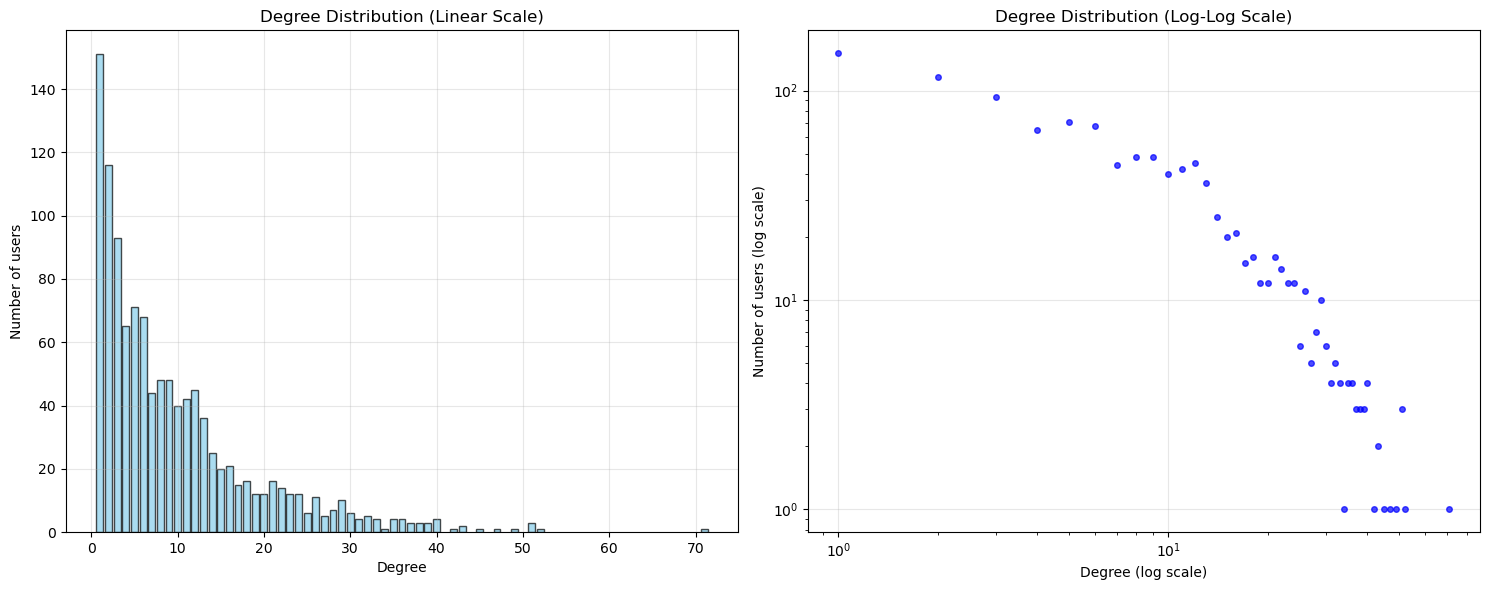


Degree Distribution Statistics:
Mean degree: 9.62
Median degree: 7.00
Max degree: 71
Min degree: 1
Standard deviation: 9.34


In [18]:
# Plot degree distribution
plot_degree_distribution(G)

## Centrality Measures Analysis

In [19]:
# Calculate centrality measures
centralities = calculate_centrality_measures(G)

Calculating centrality measures...
  - Degree centrality...
  - Betweenness centrality...
    (using sampling with k=1000 nodes)
  - Closeness centrality...
  - Eigenvector centrality...


## Comparison table

In [20]:
n = G.number_of_nodes()
m = G.number_of_edges()

degrees = [G.degree(n) for n in G.nodes()]
degree = np.mean(degrees)

G_er = er_network(n, degree)
G_ws = ws_network(n, degree)
G_ba = ba_network(n, degree)

cm_networks = {
    'Email network': G, 'Erdős-Rényi (Random) Network': G_er, 'Watts–Strogatz (Small-World) Network': G_ws, 
    'Barabási–Albert (Scale-Free) Network': G_ba} 

network_properties = {}

for name_network, value in cm_networks.items():
    network_properties[name_network] = analyse_network_properties(value)
    
# Display comparison table    
comparison_table(network_properties)


COMPARISON TABLE
Property                  Email           Erdős-Rényi     Watts–Strogatz  Barabási–Albert
------------------------------------------------------------------------------------------
Nodes (n)                 1,133               1,133               1,133           1,133          
Edges (m)                 5,451               5,479               5,665           5,640          
Average degree (<k>)      9.62                9.67                10.00           9.96           
Clustering coefficient (<C>) 0.22                0.01                0.58            0.04           
Average path length (<L>) 3.61                3.36                5.46            2.99           
Assortativity (r)         0.08                -0.00               0.01            -0.07          


## Degree distributions comparison plot

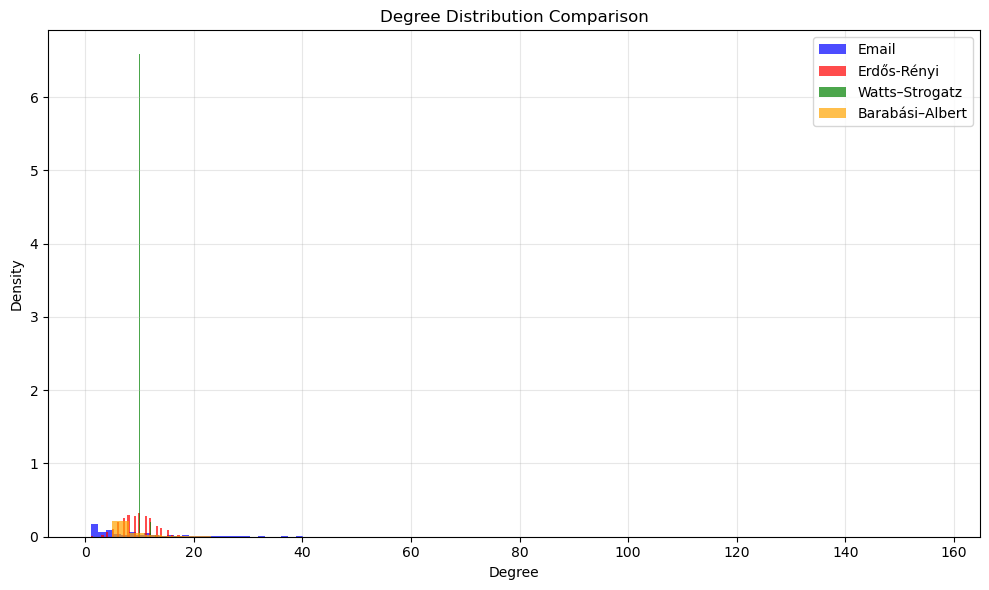

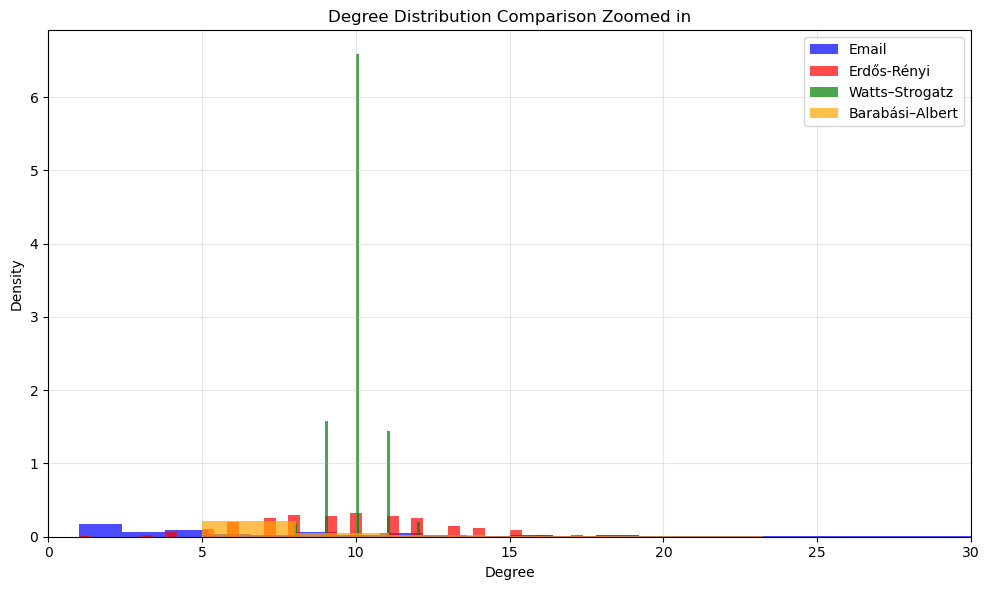

In [21]:
# Display comparison plots
comparison_plot(network_properties)

## Top Users by Centrality Measures

In [25]:
# Display top users
display_top_users(centralities, top_n=10)


TOP 10 USERS BY CENTRALITY MEASURES

DEGREE CENTRALITY:
----------------------------------------
 1.  104 - 0.062721
 2.  332 - 0.045936
 3.   15 - 0.045053
 4.   22 - 0.045053
 5.   41 - 0.045053
 6.   40 - 0.043286
 7.  195 - 0.041519
 8.  232 - 0.039753
 9.   20 - 0.037986
10.   75 - 0.037986

BETWEENNESS CENTRALITY:
----------------------------------------
 1.  332 - 0.038861
 2.  104 - 0.037220
 3.   22 - 0.035099
 4.  577 - 0.031708
 5.   75 - 0.030167
 6.  232 - 0.028810
 7.  354 - 0.027024
 8.   40 - 0.027008
 9.  134 - 0.026910
10.   41 - 0.026374

CLOSENESS CENTRALITY:
----------------------------------------
 1.  332 - 0.382820
 2.   22 - 0.381659
 3.  104 - 0.378216
 4.   41 - 0.377585
 5.   40 - 0.374959
 6.   75 - 0.374339
 7.  232 - 0.373351
 8.   51 - 0.373228
 9.  134 - 0.369935
10.  377 - 0.368610

EIGENVECTOR CENTRALITY:
----------------------------------------
 1.  104 - 0.229103
 2.   15 - 0.165296
 3.  195 - 0.154247
 4.  203 - 0.134883
 5.   41 - 0.131570
 6.   

## Additional Analysis: Centrality Comparison

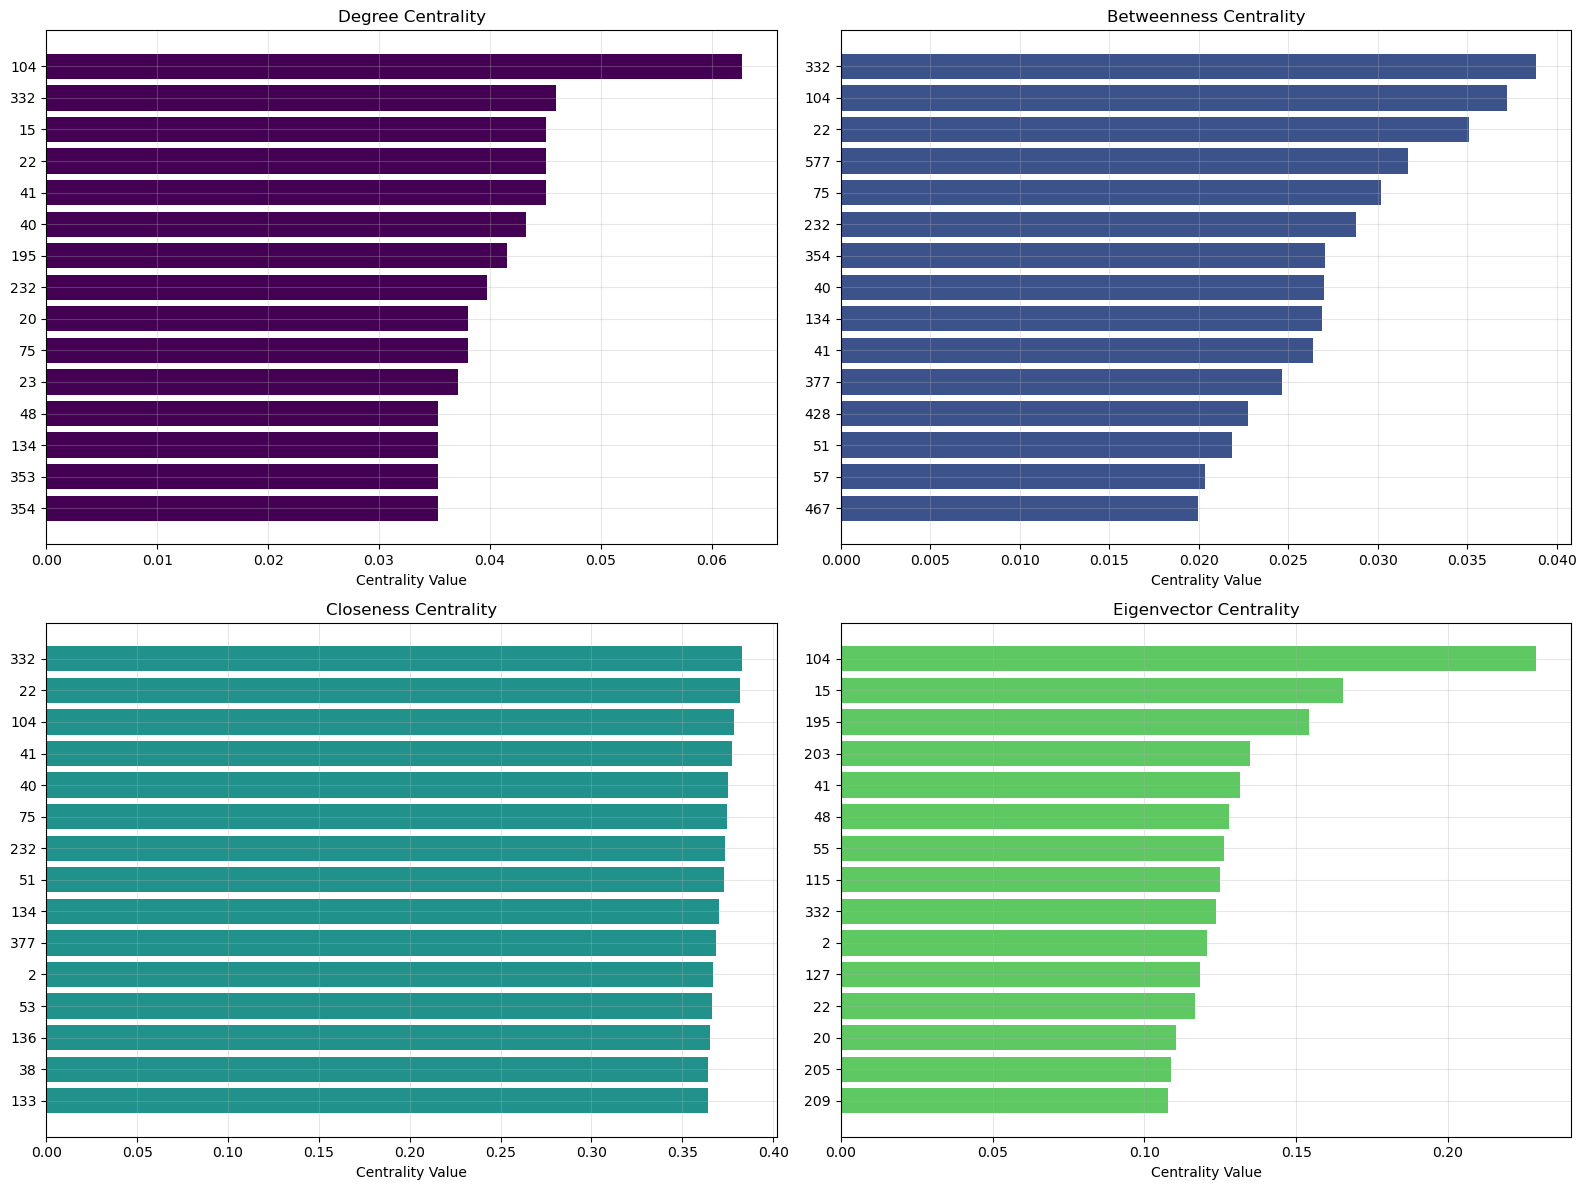

In [23]:
# Create a comparison plot of different centrality measures for top users
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

centrality_names = ['degree', 'betweenness', 'closeness', 'eigenvector']
centrality_titles = ['Degree Centrality', 'Betweenness Centrality', 'Closeness Centrality', 'Eigenvector Centrality']

for i, (name, title) in enumerate(zip(centrality_names, centrality_titles)):
    # Get top 15 users for this centrality measure
    sorted_users = sorted(centralities[name].items(), key=lambda x: x[1], reverse=True)[:15]
    users = [item[0] for item in sorted_users]
    values = [item[1] for item in sorted_users]
    
    # Create horizontal bar plot
    axes[i].barh(range(len(users)), values, color=plt.cm.viridis(i/4))
    axes[i].set_yticks(range(len(users)))
    axes[i].set_yticklabels(users)
    axes[i].set_xlabel('Centrality Value')
    axes[i].set_title(title)
    axes[i].grid(True, alpha=0.3)
    
    # Invert y-axis to show highest values at top
    axes[i].invert_yaxis()

plt.tight_layout()
plt.savefig('centrality_comparison.png', dpi=300, bbox_inches='tight')
plt.show()